# Dubai Property Price Estimator

### Context

The project aims to estimate the fair **asking price** of properties listed in Dubai. Each listing has features such as location, bedrooms, bathrooms, and property type, and a target **price**, that the model learns to predict. Sellers can use the estimated price to check whether a listing is **underpriced** or **overpriced**.

### Content of Dataset

Column 1 : **Title** represents the headline of the advertisement for this property   
Column 2 : **displayAddress** represents the location of the listing **(key feature since some locations are prime thus higher price)**  
Column 3 : **bathrooms** represents the number of bathrooms in the property **(key feature since more bathrooms means higher price )**  
Column 4 : **bedrooms** represents the number of bedrooms in the property **(key feature since more bedrooms means higher price)**  
Column 5 : **addOn** represents the date the listing was posted  
Column 6 : **type** represents the type of listing (residential or commercial)  
Column 7 : **price** represents the asking price of the property in **AED** **(Target)**  
Column 8 : **verified** represents whether the listing was verified by the portal  
Column 9 : **priceDuration** represents the time period the price covers (eg rental listings show monthly or yearly, since the data only contains properties being sold, it contains 'sell' only)  
Column 10 : **sizeMin** represents the size of the property in **square feet** **(Key feature since bigger properties mean bigger price)**  
Column 11 : **furnishing** represents whether the property is furnished, not furnished, or partly furnished



### Project Goals:

As a **supervised** regression problem, the goal of the project is:  
- Predict the asking price of UAE residential properties for sale from location, size, bedrooms, bathrooms, and furnishing.
- Explore the data to understand what drives price.
- Compare regression models and select the best one.
- Deploy the model as a web service with Docker so sellers can check whether a price is fair.


### Data Preperation:

Dataset from https://www.kaggle.com/datasets/kanchana1990/uae-real-estate-2024-dataset/data 

#### Understanding the Data

In [110]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [111]:
df = pd.read_csv('Data/uae_real_estate_2024.csv')

In [112]:
df.head()

,title,displayAddress,bathrooms,bedrooms,addedOn,type,price,verified,priceDuration,sizeMin,furnishing,description
0,Great ROI I High Floor I Creek View,"Binghatti Canal, Business Bay, Dubai",3,2,2024-08-14T12:02:53Z,Residential for Sale,2500000,True,sell,1323 sqft,NO,MNA Properties is delighted to offer this apar...
1,Full Sea View | Beach Life | Brand New Residence,"La Vie, Jumeirah Beach Residence, Dubai",3,2,2024-08-13T05:45:16Z,Residential for Sale,7200000,True,sell,1410 sqft,YES,"Apartment for sale in La Vie, Jumeirah Beach R..."
2,Green Belt | Corner Unit | Spacious Plot,"La Rosa 6, Villanova, Dubai Land, Dubai",3,4,2024-08-14T06:24:28Z,Residential for Sale,3600000,True,sell,2324 sqft,NO,Treo Homes is very pleased to be bringing to t...
3,2BR+Study | Near Pool and Park | Private,"Springs 15, The Springs, Dubai",3,2,2024-08-15T06:07:22Z,Residential for Sale,2999999,True,sell,1647 sqft,NO,2 Bedrooms + Study | Near Pool &amp; Park | Pr...
4,Vacant | Well Maintained | Area Expert,"Noor Townhouses, Town Square, Dubai",3,3,2024-08-09T08:28:59Z,Residential for Sale,2449999,True,sell,2105 sqft,NO,-Type 1\n-3 Bed+Maid\n-Close To Amenities\n-BU...


In [113]:
print(f'The dataset has {df.shape[0]} rows and {df.shape[1]} columns')

The dataset has 5058 rows and 12 columns


In [114]:
df.sample(5) #Picks randomly 5 rows (more data can be seen )

,title,displayAddress,bathrooms,bedrooms,addedOn,type,price,verified,priceDuration,sizeMin,furnishing,description
1530,Spacious | Canal View | Q4 2025,"Laurel, Central Park at City Walk, City Walk, ...",1,1,2024-07-25T12:41:16Z,Residential for Sale,1950000,True,sell,755 sqft,NO,M &amp; E is delighted to offer you this 1 Bed...
1765,High Floor | Canal View | Best Price | Close t...,"Society House, Downtown Dubai, Dubai",2,1,2024-08-07T12:53:24Z,Residential for Sale,2150000,True,sell,705 sqft,NO,"1 bedroom apartment located in Society House, ..."
929,Motivated Seller| Biggest Plot | Q3-2026,"Opal Gardens, District 11, Mohammed Bin Rashid...",5,4,2024-07-16T10:25:07Z,Residential for Sale,6600000,True,sell,4851 sqft,NO,GOLD MARK REAL ESTATE is pleased to present a ...
283,Luxury Palm Island Living | High Appreciation,"Frond K, Signature Villas, Palm Jebel Ali, Dubai",7,6,2024-08-14T14:09:40Z,Residential for Sale,20578800,False,sell,7377 sqft,NO,Ahsan Aslam from Trex Properties LLC proudly p...
4204,0% commission | 4% DLD waiver | Luxurious Villa,"The Acres, Dubai Land, Dubai",6,5,2024-08-12T13:05:09Z,Residential for Sale,8825000,False,sell,4962 sqft,NO,Positive Properties LLC is delighted to showca...


In [115]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5058 entries, 0 to 5057
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   title           5058 non-null   str  
 1   displayAddress  5058 non-null   str  
 2   bathrooms       4938 non-null   str  
 3   bedrooms        4935 non-null   str  
 4   addedOn         5058 non-null   str  
 5   type            5058 non-null   str  
 6   price           5058 non-null   int64
 7   verified        5058 non-null   bool 
 8   priceDuration   5058 non-null   str  
 9   sizeMin         5058 non-null   str  
 10  furnishing      5056 non-null   str  
 11  description     5057 non-null   str  
dtypes: bool(1), int64(1), str(10)
memory usage: 439.7 KB


In [116]:
df.dtypes[df.dtypes == 'str'].index # finds all columns that are strings 

Index(['title', 'displayAddress', 'bathrooms', 'bedrooms', 'addedOn', 'type',
       'priceDuration', 'sizeMin', 'furnishing', 'description'],
      dtype='str')

We will need to clean the data since most numerical features are strings therefore we will have to change them back

In [117]:
df.dtypes

title               str
displayAddress      str
bathrooms           str
bedrooms            str
addedOn             str
type                str
price             int64
verified           bool
priceDuration       str
sizeMin             str
furnishing          str
description         str
dtype: object

In [118]:
df.isna().sum() #Since the values that are missing less than 50% for all the column we can fill them rather than removing them  

title               0
displayAddress      0
bathrooms         120
bedrooms          123
addedOn             0
type                0
price               0
verified            0
priceDuration       0
sizeMin             0
furnishing          2
description         1
dtype: int64

In [119]:
df.describe()

,price
count,5.058000e+03
mean,5.050924e+06
std,1.000928e+07
min,1.000000e+05
25%,1.200000e+06
50%,2.350000e+06
75%,4.499375e+06
max,1.990000e+08


Are there any duplicate observations?

In [120]:
df.duplicated(keep ='first').sum() 

np.int64(0)

There are 0 duplicated columns in the dataset 

### Drop features priceDuration and type 

Since the features priceDuration and type are always the same having them won't impact the model.The feature type is always 'residential for sale' and the priceDuration is always 'year' thus they are not impacting price 

In [121]:
df['priceDuration'].unique(), df['type'].unique()

(<StringArray>
 ['sell']
 Length: 1, dtype: str,
 <StringArray>
 ['Residential for Sale']
 Length: 1, dtype: str)

In [122]:
df = df.drop(['priceDuration','type'], axis = 1)

In [123]:
df 

,title,displayAddress,bathrooms,bedrooms,addedOn,price,verified,sizeMin,furnishing,description
0,Great ROI I High Floor I Creek View,"Binghatti Canal, Business Bay, Dubai",3,2,2024-08-14T12:02:53Z,2500000,True,1323 sqft,NO,MNA Properties is delighted to offer this apar...
1,Full Sea View | Beach Life | Brand New Residence,"La Vie, Jumeirah Beach Residence, Dubai",3,2,2024-08-13T05:45:16Z,7200000,True,1410 sqft,YES,"Apartment for sale in La Vie, Jumeirah Beach R..."
2,Green Belt | Corner Unit | Spacious Plot,"La Rosa 6, Villanova, Dubai Land, Dubai",3,4,2024-08-14T06:24:28Z,3600000,True,2324 sqft,NO,Treo Homes is very pleased to be bringing to t...
3,2BR+Study | Near Pool and Park | Private,"Springs 15, The Springs, Dubai",3,2,2024-08-15T06:07:22Z,2999999,True,1647 sqft,NO,2 Bedrooms + Study | Near Pool &amp; Park | Pr...
4,Vacant | Well Maintained | Area Expert,"Noor Townhouses, Town Square, Dubai",3,3,2024-08-09T08:28:59Z,2449999,True,2105 sqft,NO,-Type 1\n-3 Bed+Maid\n-Close To Amenities\n-BU...
...,...,...,...,...,...,...,...,...,...,...
5053,07 Layout | Handover Q2 2025 | Multiple Units ...,"Sobha Creek Vistas Grande, Sobha Hartland, Moh...",3,2,2024-07-10T14:07:57Z,2345000,True,1268 sqft,PARTLY,Nobel Victory Real Estate are proud to present...
5054,Emaar | Waterfront Apartment | 10% DP | 5-Yr PP,"Al Marjan Island, Ras Al Khaimah",2,1,2024-08-12T13:08:33Z,3007888,False,854 sqft,NO,"Discover Address Residence by Emaar, nestled o..."
5055,Upgraded | Spacious With Private Garden,"Oia Residence, Motor City, Dubai",5,4,2024-04-20T08:43:16Z,4000000,True,3813 sqft,NO,Rocky Real Estate presents an Exclusive and up...
5056,"10 Series | Full Sea, Burj Khalifa View Exclusive","The Grand, Dubai Creek Harbour (The Lagoons), ...",2,2,2024-07-08T07:05:56Z,3800000,True,1300 sqft,NO,Dingstone Real Estate is pleased to present to...


#### Data cleaning and Feature Engineering

In [124]:
df['sizeMin'].head()

0    1323 sqft
1    1410 sqft
2    2324 sqft
3    1647 sqft
4    2105 sqft
Name: sizeMin, dtype: str

In [125]:
df['size_sqft'] = df['sizeMin'].str.replace('sqft','').str.strip() 

In [126]:
df['size_sqft'] = df['size_sqft'].astype('float64')

In [127]:
df['size_sqft']

0       1323.0
1       1410.0
2       2324.0
3       1647.0
4       2105.0
         ...  
5053    1268.0
5054     854.0
5055    3813.0
5056    1300.0
5057    3685.0
Name: size_sqft, Length: 5058, dtype: float64

In [128]:
df.head()

,title,displayAddress,bathrooms,bedrooms,addedOn,price,verified,sizeMin,furnishing,description,size_sqft
0,Great ROI I High Floor I Creek View,"Binghatti Canal, Business Bay, Dubai",3,2,2024-08-14T12:02:53Z,2500000,True,1323 sqft,NO,MNA Properties is delighted to offer this apar...,1323.0
1,Full Sea View | Beach Life | Brand New Residence,"La Vie, Jumeirah Beach Residence, Dubai",3,2,2024-08-13T05:45:16Z,7200000,True,1410 sqft,YES,"Apartment for sale in La Vie, Jumeirah Beach R...",1410.0
2,Green Belt | Corner Unit | Spacious Plot,"La Rosa 6, Villanova, Dubai Land, Dubai",3,4,2024-08-14T06:24:28Z,3600000,True,2324 sqft,NO,Treo Homes is very pleased to be bringing to t...,2324.0
3,2BR+Study | Near Pool and Park | Private,"Springs 15, The Springs, Dubai",3,2,2024-08-15T06:07:22Z,2999999,True,1647 sqft,NO,2 Bedrooms + Study | Near Pool &amp; Park | Pr...,1647.0
4,Vacant | Well Maintained | Area Expert,"Noor Townhouses, Town Square, Dubai",3,3,2024-08-09T08:28:59Z,2449999,True,2105 sqft,NO,-Type 1\n-3 Bed+Maid\n-Close To Amenities\n-BU...,2105.0


In [129]:
df['bathrooms'].value_counts()

bathrooms
2       1209
1       1038
3        902
4        686
5        511
6        273
7        206
7+       112
none       1
Name: count, dtype: int64

In [130]:
df['bathrooms'] = df['bathrooms'].replace({'7+':'7','none': np.nan})

In [131]:
df['bathrooms'].value_counts()

bathrooms
2    1209
1    1038
3     902
4     686
5     511
7     318
6     273
Name: count, dtype: int64

In [132]:
df['bathrooms'] = df['bathrooms'].astype('float64')

In [133]:
df['bathrooms'].value_counts(dropna = False)

bathrooms
2.0    1209
1.0    1038
3.0     902
4.0     686
5.0     511
7.0     318
6.0     273
NaN     121
Name: count, dtype: int64

Bathroom feature cleanup:
It was stored as text in the data and contained two non numerical values ( **'7+'** and **'none'**)  

- **7+** (112 listings): replaced with **7**. This treats "7 or more" as 7, a small simplification that merges these listings with the existing 7-bathroom group.
- **none** (1 listing): replaced with **NaN**. A property with no bathroom is most likely missing data, so it is handled together with the other missing values.

After this step the column can be converted to a numeric type, and the missing values (about 121) can be filled later.

In [134]:
df['bedrooms'].value_counts()

bedrooms
1         1265
2         1088
3          799
4          714
studio     541
5          366
6          122
7           25
7+          15
Name: count, dtype: int64

In [135]:
df['bedrooms'] = df['bedrooms'].replace({'studio':'0', '7+':'7'})

In [136]:
df['bedrooms'].isna().sum()

np.int64(123)

In [137]:
df['bedrooms'] = df['bedrooms'].astype('float64')

In [138]:
df.sample(5)

,title,displayAddress,bathrooms,bedrooms,addedOn,price,verified,sizeMin,furnishing,description,size_sqft
1072,Double Row | Spacious 3BR+1 | Gated Community,"Al Ghadeer 2, Al Ghadeer, Abu Dhabi",4.0,3.0,2024-06-21T05:25:56Z,2100000,True,1695 sqft,NO,"Beautifully-maintained, unfurnished, 3-bedroom...",1695.0
1126,Modern Unit | High Floor with Canal View,"South Ridge 6, South Ridge, Downtown Dubai, Dubai",2.0,1.0,2024-07-29T09:45:35Z,1950000,True,1060 sqft,NO,"Brought to you by Driven Properties, this 1 Be...",1060.0
1517,VOT | Investment Opportunity | Good Location,"Binghatti Gems, Jumeirah Village Circle, Dubai",1.0,1.0,2024-07-29T09:45:34Z,750000,True,663 sqft,NO,"Brought to you by Driven Properties, this 1 Be...",663.0
2765,UPGRADED | PRIVATE POOL | CORNER PLOT | VOT,"Springs 10, The Springs, Dubai",4.0,3.0,2024-07-04T05:07:25Z,4800000,True,2000 sqft,NO,Property Details:\n\n- Converted and Rennovate...,2000.0
256,URGENT SALE | OP PRICE | PARK ACCESS,"Park Horizon, Dubai Hills Estate, Dubai",2.0,2.0,2024-08-14T07:08:04Z,2200000,True,1033 sqft,NO,URGENT SALE | OP PRICE | PARK ACCESS<br><br>St...,1033.0


Bedrooms feature cleanup:
It was stored as text in the data and contained two non numerical values ( **'studio'** and **'7+'**)  

- **7+** (15 listings): replaced with **7**. This treats "7 or more" as 7, a small simplification that merges these listings with the existing 7-bedroom group.
- **studio** (541 listings): replaced with **0**. A studio property has zero seperate bedrooms thus replaced it with 0.

After this step the column can be converted to a numeric type (float) since the data had NaN values, and the missing values (about 123) can be filled later.

In [139]:
df['furnishing'] = df['furnishing'].str.capitalize()

In [140]:
df['furnishing'].unique()

<StringArray>
['No', 'Yes', 'Partly', nan]
Length: 4, dtype: str

In [141]:
df[['sizeMin', 'size_sqft']].sample(5)

,sizeMin,size_sqft
4326,755 sqft,755.0
3861,460 sqft,460.0
3957,3014 sqft,3014.0
151,960 sqft,960.0
340,3552 sqft,3552.0


In [142]:
df['size_sqft'].isna().sum()

np.int64(0)

In [143]:
df = df.drop(['sizeMin'], axis = 1 )

Since feature sizeMin contained text (eg 1800 sqft), we just made the value numerical and dropped the sqft unit to make size_sqft and dropped the old one since they represent the same information.

In [144]:
df.head(5)

,title,displayAddress,bathrooms,bedrooms,addedOn,price,verified,furnishing,description,size_sqft
0,Great ROI I High Floor I Creek View,"Binghatti Canal, Business Bay, Dubai",3.0,2.0,2024-08-14T12:02:53Z,2500000,True,No,MNA Properties is delighted to offer this apar...,1323.0
1,Full Sea View | Beach Life | Brand New Residence,"La Vie, Jumeirah Beach Residence, Dubai",3.0,2.0,2024-08-13T05:45:16Z,7200000,True,Yes,"Apartment for sale in La Vie, Jumeirah Beach R...",1410.0
2,Green Belt | Corner Unit | Spacious Plot,"La Rosa 6, Villanova, Dubai Land, Dubai",3.0,4.0,2024-08-14T06:24:28Z,3600000,True,No,Treo Homes is very pleased to be bringing to t...,2324.0
3,2BR+Study | Near Pool and Park | Private,"Springs 15, The Springs, Dubai",3.0,2.0,2024-08-15T06:07:22Z,2999999,True,No,2 Bedrooms + Study | Near Pool &amp; Park | Pr...,1647.0
4,Vacant | Well Maintained | Area Expert,"Noor Townhouses, Town Square, Dubai",3.0,3.0,2024-08-09T08:28:59Z,2449999,True,No,-Type 1\n-3 Bed+Maid\n-Close To Amenities\n-BU...,2105.0


## Feature Engineering 

### Extracting 'city' and 'community' 


'displayAddress' has many unique values thus can't be used directly. However it follows the pattern 'building,community, city' therefore it was split into two important features city (last part) and the community (middle part)

In [145]:
def find_city(details):
    details = details.split(',')
    city = details[-1].strip()
    return city

In [146]:
df['City'] = df['displayAddress'].apply(find_city)

In [147]:
df.sample(5)

,title,displayAddress,bathrooms,bedrooms,addedOn,price,verified,furnishing,description,size_sqft,City
3343,"⚡ 1,973 Sqm | Single Row Waterfront Plot! ⚡","Lea, Yas Acres, Yas Island, Abu Dhabi",NaN,NaN,2024-08-15T14:23:59Z,7299990,False,No,"⚡ 1,973 Sqm | Single Row Waterfront Plot! ⚡\n\...",21237.0,Abu Dhabi
921,Motivated Seller | High Floor | Boulevard View,"BLVD Heights Tower 1, BLVD Heights, Downtown D...",4.0,3.0,2024-07-24T13:27:22Z,6500000,True,No,A sumptuous selection of 3-bedroom apartments ...,2363.0,Dubai
4746,20% DownPayment I Aston Martin Residences I Beach,"The Astera Interiors by Aston Martin, Al Marja...",2.0,2.0,2024-08-03T11:32:14Z,2834755,False,No,Property on Al Marjan Island - Island #4\nBeac...,1107.0,Ras Al Khaimah
4439,"Elegant 2-BR + Study in Oakley Square, JVC","Oakley Square Residences, Jumeirah Village Cir...",3.0,2.0,2024-07-02T09:09:16Z,1900000,True,No,Al Hilal Property is delighted to present this...,1189.0,Dubai
351,Community Specialist | Vacant | 2E,"Maple 3, Maple at Dubai Hills Estate, Dubai Hi...",3.0,4.0,2024-07-11T12:29:11Z,4999999,True,No,Community Specialist | Vacant | 2E\n\n-Type 2E...,2462.0,Dubai


In [148]:
def find_community(details):
    details = details.split(',')
    community = details[-2].strip()
    return community

In [149]:
df['Community'] = df['displayAddress'].apply(find_community)

In [150]:
df.sample(5)

,title,displayAddress,bathrooms,bedrooms,addedOn,price,verified,furnishing,description,size_sqft,City,Community
185,2 Bed | Vacant | DIFC Views | Sky Gaydens,"Sky Gardens, DIFC, Dubai",2.0,2.0,2024-01-26T08:05:28Z,2850000,True,No,2 Bed | Vacant | DIFC Views | Sky Gaydens\n\n-...,1662.0,Dubai,DIFC
4724,High ROI I Best Price I Payment Plan,"Sobha One, Ras Al Khor Industrial, Ras Al Khor...",1.0,1.0,2024-07-16T12:14:57Z,1450000,True,No,Beacon Houses Real Estate is delighted to offe...,550.0,Dubai,Ras Al Khor
574,Luxury Villa | Strategic Location | Resale,"Al Zaheya Gardens, Al Zahya, Ajman",4.0,3.0,2024-08-05T13:34:11Z,2000000,False,No,&#34;This exceptional villa showcases a harmon...,3081.0,Ajman,Al Zahya
1242,Single Row | Corner | Executive 4BR | Prime Li...,"Al Jubail Island, Abu Dhabi",7.0,4.0,2024-07-26T09:06:13Z,6500000,False,No,Exceptional 4-Bedroom Townhouse for Sale in Al...,5088.0,Abu Dhabi,Al Jubail Island
3097,Fully Furnished | VOT | Community View,"Miraclz Tower by Danube, Arjan, Dubai",1.0,0.0,2024-04-11T10:04:56Z,550000,True,Yes,Lacon International is pleased to introduce th...,391.0,Dubai,Arjan


In [151]:
df['City'].value_counts(dropna = False) 

City
Dubai             4031
Abu Dhabi          370
Sharjah            267
Ras Al Khaimah     201
Ajman              170
Umm Al Quwain       11
Fujairah             4
Al Ain               4
Name: count, dtype: int64

In [152]:
df['Community'].nunique()

190

In [153]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5058 entries, 0 to 5057
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   title           5058 non-null   str    
 1   displayAddress  5058 non-null   str    
 2   bathrooms       4937 non-null   float64
 3   bedrooms        4935 non-null   float64
 4   addedOn         5058 non-null   str    
 5   price           5058 non-null   int64  
 6   verified        5058 non-null   bool   
 7   furnishing      5056 non-null   str    
 8   description     5057 non-null   str    
 9   size_sqft       5058 non-null   float64
 10  City            5058 non-null   str    
 11  Community       5058 non-null   str    
dtypes: bool(1), float64(3), int64(1), str(7)
memory usage: 439.7 KB


### Dropping unused columns 

- 'displayAddress' : replaced by extracted features like 'Community' and 'City'  
- 'addedOn' : Almost all the listings were posted in mid of 2024, thus the date adds little info about the price and most sellers that use the estimator would always be using the listing 'today', a date that the model has never seen.
- 'description' : Long text containing details about the real estate brokerage company that is not usefull for the model

In [154]:
df = df.drop(['displayAddress','addedOn','description'], axis = 1)

In [155]:
df.head()

,title,bathrooms,bedrooms,price,verified,furnishing,size_sqft,City,Community
0,Great ROI I High Floor I Creek View,3.0,2.0,2500000,True,No,1323.0,Dubai,Business Bay
1,Full Sea View | Beach Life | Brand New Residence,3.0,2.0,7200000,True,Yes,1410.0,Dubai,Jumeirah Beach Residence
2,Green Belt | Corner Unit | Spacious Plot,3.0,4.0,3600000,True,No,2324.0,Dubai,Dubai Land
3,2BR+Study | Near Pool and Park | Private,3.0,2.0,2999999,True,No,1647.0,Dubai,The Springs
4,Vacant | Well Maintained | Area Expert,3.0,3.0,2449999,True,No,2105.0,Dubai,Town Square


In [156]:
df[df['bedrooms'].isna()].sample(10)

,title,bathrooms,bedrooms,price,verified,furnishing,size_sqft,City,Community
463,"Call Palm Jebel Ali experts ,No Commission cha...",NaN,NaN,38438800,False,No,13993.0,Dubai,Palm Jebel Ali
4990,G+4 Plot / Directly On The Park / Single Row,NaN,NaN,4200000,False,No,10000.0,Dubai,Jebel Ali
4199,Invest in a Prime Location for Your Dream Villa,NaN,NaN,630000,False,No,3014.0,Ajman,Al Yasmeen
4614,land for sale on tallah Street for commercial use,NaN,NaN,5500000,False,No,17223.0,Ajman,Al Rawda
2444,Direct Sea View | Single Row | Negotiable,NaN,NaN,40000000,False,No,9755.0,Dubai,Jumeirah
2665,Single Row Mid | Waterfront | Prime Location,NaN,NaN,8700000,False,No,10501.0,Abu Dhabi,Al Qurm
505,"G+24 Residential Plot, Multiple Options for sale",NaN,NaN,35000000,False,No,26968.0,Dubai,Downtown Jebel Ali
3835,G+2 Villa Plot For Sale In Al Helio Ajman,NaN,NaN,530000,False,No,3014.0,Ajman,Al Helio
3856,Corner Plot | Multiple Options | Genuine Resale,NaN,NaN,6500000,False,No,5000.0,Dubai,Nad Al Sheba
335,"Land for sale in Ajman, Al Zahya area, , corner",NaN,NaN,360000,False,No,2200.0,Ajman,Al Zahya


In [157]:
df[df['bedrooms'].isna()]['price'].describe()

count    1.230000e+02
mean     9.614613e+06
std      1.770877e+07
min      1.250000e+05
25%      7.375000e+05
50%      2.200000e+06
75%      8.850000e+06
max      9.900000e+07
Name: price, dtype: float64

In [158]:
df['price'].describe()

count    5.058000e+03
mean     5.050924e+06
std      1.000928e+07
min      1.000000e+05
25%      1.200000e+06
50%      2.350000e+06
75%      4.499375e+06
max      1.990000e+08
Name: price, dtype: float64

From the comparison where the 'bedroom' values are missing, we can see that the mean and quartile 3 for them have doubled compared to all the listings median and 3rd quartile. Therefore, more values are expensive; therefore, the mean sits at the upper end since it gets affected by the outliers. Therefore, we can assume that these are land plots, whole buildings, or other listings where bedrooms don't apply. If that's the case, we can't fill them since it doesn't apply to that field; thus, we can't fill them with the median values. 

In [159]:
df[df['bedrooms'].isna()].sort_values('price', ascending=False).head(10)[["title", "Community", "size_sqft", "bathrooms", "price"]]

,title,Community,size_sqft,bathrooms,price
427,Luxurious &amp; Elegant | Ready 2025 | Sea View,Jumeirah,12651.0,NaN,99000000
1554,Huge Residential Plot | Private Beach Access,Palm Jumeirah,12142.0,NaN,85566000
3978,Prestigious | Beach Access | Freehold,Jumeirah,26307.0,NaN,80000000
3071,"G+14 Mix use Plot,The Best Location",Al Jaddaf,62803.0,NaN,75363600
431,"Direct Beachfront And Corner Plot, One Of The ...",Jumeirah,12933.0,NaN,52000000
4426,Payment Plan - No Agency Fees - DLD Fees Waiver,Palm Jebel Ali,13993.0,NaN,42618800
461,"3 years Payment Plan, No Commission Charges",Palm Jebel Ali,13993.0,NaN,41408800
4866,Beachfront Plot | Beach Access | Waterfront Li...,Palm Jebel Ali,13993.0,NaN,41408800
4424,Villa Plot - G+2 - Payment Plan - DLD Fees Waiver,Palm Jebel Ali,13993.0,NaN,40428800
2444,Direct Sea View | Single Row | Negotiable,Jumeirah,9755.0,NaN,40000000


Most of the listings with missing bedrooms are either land plots or full buildings. Since the model estimates the prices of residential units (apartment,villas and townhouses), keeping them would add noise. 

### Exploratory Data Analysis 

In [160]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5058 entries, 0 to 5057
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   title       5058 non-null   str    
 1   bathrooms   4937 non-null   float64
 2   bedrooms    4935 non-null   float64
 3   price       5058 non-null   int64  
 4   verified    5058 non-null   bool   
 5   furnishing  5056 non-null   str    
 6   size_sqft   5058 non-null   float64
 7   City        5058 non-null   str    
 8   Community   5058 non-null   str    
dtypes: bool(1), float64(3), int64(1), str(4)
memory usage: 321.2 KB


In [161]:
df.corr(numeric_only = True)

,bathrooms,bedrooms,price,verified,size_sqft
bathrooms,1.000000,0.931164,0.461971,-0.172192,0.648345
bedrooms,0.931164,1.000000,0.484829,-0.115722,0.667599
price,0.461971,0.484829,1.000000,0.015077,0.609647
verified,-0.172192,-0.115722,0.015077,1.000000,-0.142109
size_sqft,0.648345,0.667599,0.609647,-0.142109,1.000000


- size_sqft has the strongest positive correlation with price (0.609647), followed by bedrooms (0.484829) and then bathrooms(0.461971)  
- bathrooms and bedrooms are really strongly postively correlated (0.931164)

In [162]:
df.head(5)

,title,bathrooms,bedrooms,price,verified,furnishing,size_sqft,City,Community
0,Great ROI I High Floor I Creek View,3.0,2.0,2500000,True,No,1323.0,Dubai,Business Bay
1,Full Sea View | Beach Life | Brand New Residence,3.0,2.0,7200000,True,Yes,1410.0,Dubai,Jumeirah Beach Residence
2,Green Belt | Corner Unit | Spacious Plot,3.0,4.0,3600000,True,No,2324.0,Dubai,Dubai Land
3,2BR+Study | Near Pool and Park | Private,3.0,2.0,2999999,True,No,1647.0,Dubai,The Springs
4,Vacant | Well Maintained | Area Expert,3.0,3.0,2449999,True,No,2105.0,Dubai,Town Square


#### Univariate Analysis 

##### Discrete Numeric Features

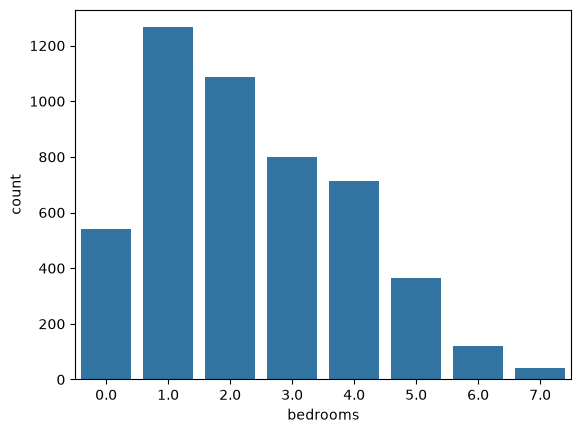

In [163]:
bedrooms = sns.countplot(x = df["bedrooms"])

In [164]:
df['bedrooms'].value_counts()

bedrooms
1.0    1265
2.0    1088
3.0     799
4.0     714
0.0     541
5.0     366
6.0     122
7.0      40
Name: count, dtype: int64

Most of the Data is of 1 bedrooms properties (1265), followed by 2 bedroom properties (1088) therefore both of these values account for almost **half** of the data in the dataset. Studio properties are 541 thus the model can also learn from the studio listings. We can also observe a decline from bedrooms 3 and above, 799 listings of 3 bedroom, 714 listings of 4 bedrooms and 366 listings of 5 bedroom properties. Large homes are **rare** with 6 bedroms 122 listings and 7 bedrooms 40 listings.

Since most data is on **small homes and apartments** thus model will predict them the **best**, however the predictions for **larger houses** with 6 to 7 bedrooms will be **less reliable** due to the lack of data the model was trained for those listings.

<Axes: >

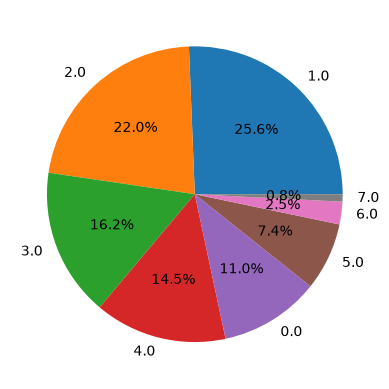

In [165]:
df['bedrooms'].value_counts().plot(kind = 'pie', autopct='%1.1f%%')

C:\Users\USER\AppData\Local\Temp\ipykernel_10932\4154995891.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  bathrooms.set_xticklabels([1,2,3,4,5,6,7])


[Text(0, 0, '1'),
 Text(1, 0, '2'),
 Text(2, 0, '3'),
 Text(3, 0, '4'),
 Text(4, 0, '5'),
 Text(5, 0, '6'),
 Text(6, 0, '7')]

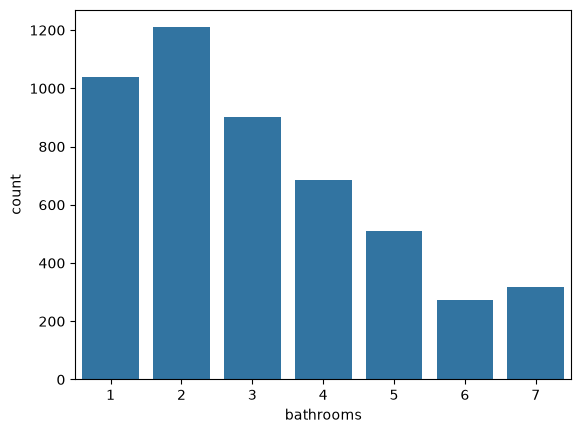

In [166]:
bathrooms = sns.countplot(x = df['bathrooms'])
bathrooms.set_xticklabels([1,2,3,4,5,6,7])

Most properties have 2 bathrooms, followed by 1 bathroom with only a few properties having 6 or more bathrooms, thus the model will be trained well on properties with fewer bathrooms like apartments or small homes, not on larger houses who's predictions will be less reliable due to few listings in our dataset

<Axes: >

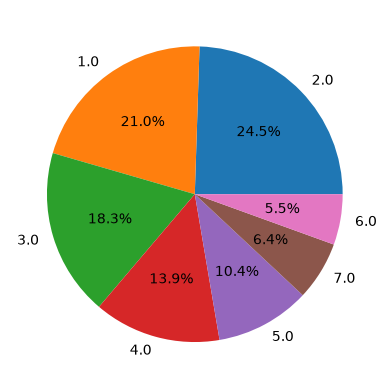

In [167]:
df['bathrooms'].value_counts().plot(kind = 'pie', autopct='%1.1f%%')

##### Categorical Features

Text(0.5, 1.0, 'Properties Furnishing')

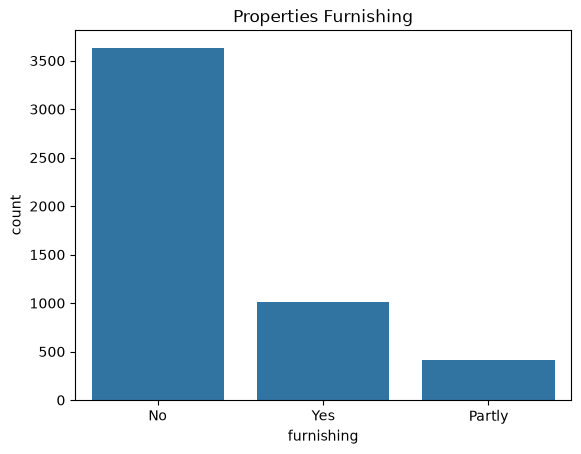

In [168]:
furnished = sns.countplot(x = df['furnishing'])
plt.title('Properties Furnishing')

<Axes: >

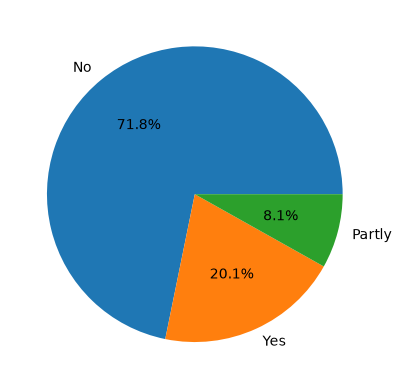

In [169]:
df['furnishing'].value_counts().plot(kind = 'pie', autopct='%1.1f%%')

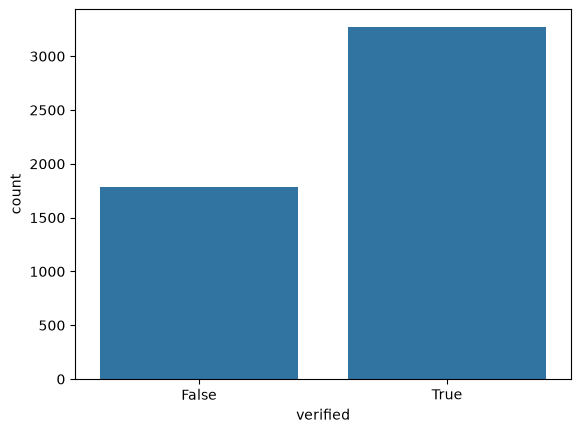

In [170]:
furnished = sns.countplot(x = df['verified'])

Text(0.5, 1.0, 'Listings per City')

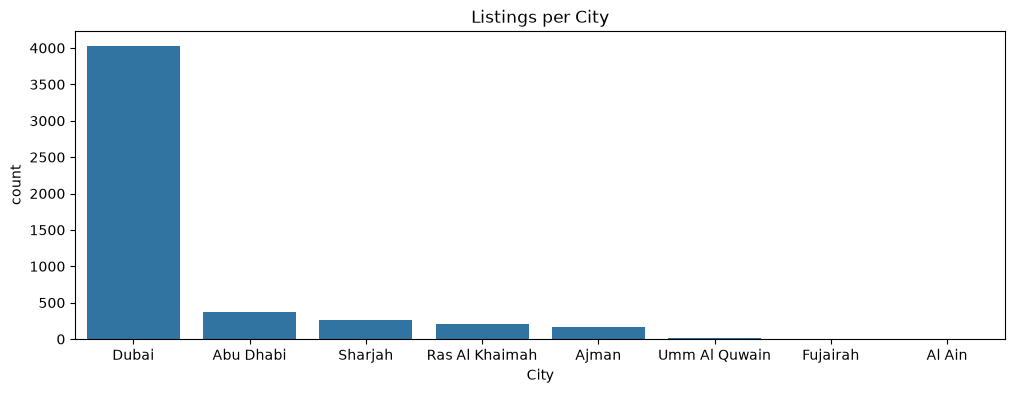

In [171]:
plt.figure(figsize = (12,4))
furnished = sns.countplot(x = df['City'], order = df['City'].value_counts().index)
plt.title('Listings per City')

In [172]:
df['City'].value_counts()

City
Dubai             4031
Abu Dhabi          370
Sharjah            267
Ras Al Khaimah     201
Ajman              170
Umm Al Quwain       11
Fujairah             4
Al Ain               4
Name: count, dtype: int64

In [173]:
df.columns 

Index(['title', 'bathrooms', 'bedrooms', 'price', 'verified', 'furnishing',
       'size_sqft', 'City', 'Community'],
      dtype='str')

Text(0.5, 1.0, 'Top 15 Communities by number of listings')

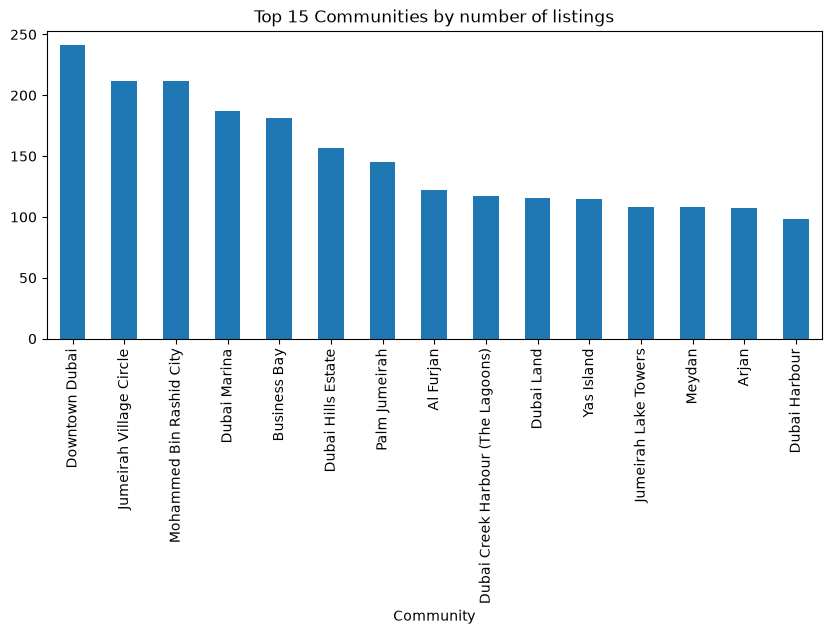

In [174]:
plt.figure(figsize = (10,4))
df["Community"].value_counts().head(15).plot(kind="bar")
plt.title("Top 15 Communities by number of listings")

In [175]:
df["Community"].value_counts().head(15)

Community
Downtown Dubai                       241
Jumeirah Village Circle              212
Mohammed Bin Rashid City             212
Dubai Marina                         187
Business Bay                         181
Dubai Hills Estate                   157
Palm Jumeirah                        145
Al Furjan                            122
Dubai Creek Harbour (The Lagoons)    117
Dubai Land                           116
Yas Island                           115
Jumeirah Lake Towers                 108
Meydan                               108
Arjan                                107
Dubai Harbour                         98
Name: count, dtype: int64

The top communities that are found in the listing are from Dubai like Downtown Dubai, JVC (Jumairah Village Circle) and Mohammed Bin Rashid City 

In [176]:
df["Community"].nunique()

190

In [177]:
sum(df['Community'].value_counts() < 10)

98

##### Numeric Features

In [178]:
df['price'].describe()

count    5.058000e+03
mean     5.050924e+06
std      1.000928e+07
min      1.000000e+05
25%      1.200000e+06
50%      2.350000e+06
75%      4.499375e+06
max      1.990000e+08
Name: price, dtype: float64

In [179]:
df.shape 

(5058, 9)

**Removing non-residential listings before EDA**

- These rows are removed prior to EDA since the model estimates the prices of residential properties (apartment, house, townhouse) and plots and buildings follow different pricing rules
- Their extreme sizes and prices would stretch the distributions, plots, and correlations, making the analysis of normal listings less clear.
- These values can't be filled since we would be inventing bedrooms and bathrooms for properties that have none.


In [180]:
df = df.dropna(subset = ['bedrooms']).reset_index(drop = True)

In [181]:
df.shape

(4935, 9)

In [182]:
df['price'].describe()

count    4.935000e+03
mean     4.937178e+06
std      9.715803e+06
min      1.000000e+05
25%      1.200000e+06
50%      2.350000e+06
75%      4.401944e+06
max      1.990000e+08
Name: price, dtype: float64

In [183]:
df.isna().sum()

title         0
bathrooms     3
bedrooms      0
price         0
verified      0
furnishing    2
size_sqft     0
City          0
Community     0
dtype: int64

Text(0.5, 1.0, 'Price Histogram')

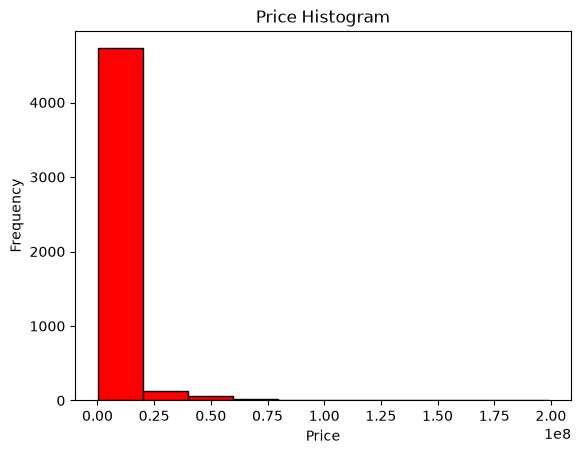

In [184]:
plt.hist(df['price'], bins = 10, color = 'red', edgecolor = 'Black')
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Price Histogram")

Text(0.5, 0, 'log (Price + 1)')

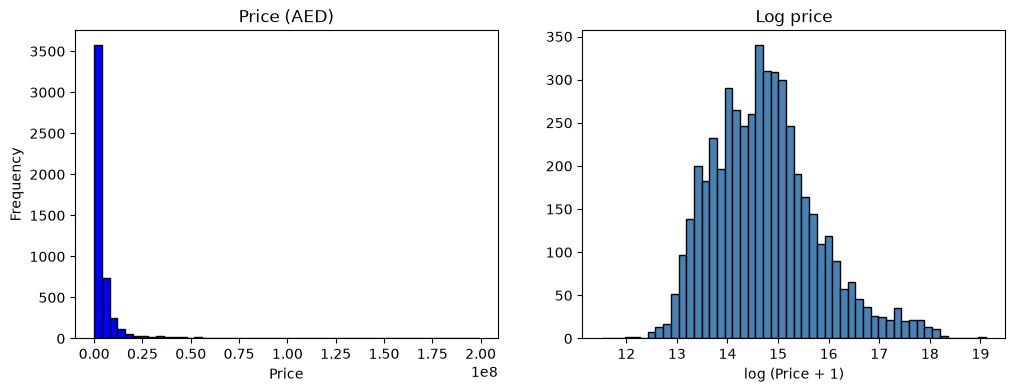

In [185]:
fig, axes = plt.subplots(1,2, figsize = (12,4))

axes[0].hist(df['price'], bins=50, color="blue", edgecolor="black")
axes[0].set_title("Price (AED)")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Frequency")

axes[1].hist(np.log1p(df["price"]), bins=50, color="steelblue", edgecolor="black")
axes[1].set_title("Log price")
axes[1].set_xlabel("log (Price + 1)")


The Price is **strongly right skewed** with most listings below 20M AED, while a few reach 200 million, the standard deviation (about 9.7M) is twice the mean (about 4.9M). After applying the 'np.log1p', we observe the distribution closer to a bell shape, centered around 2.4 million AED (the median is 2.35M), with a mild remaining right tail.

Therefore Training directly on this target would allow for the model to focus on the very few expensive listings errors avoiding fixing errors of listing below 20M that are mostly found in the dataset. Thus log transform ('np.log1p') will be applied to 'price' for modeling. 

In [186]:
df['price'].sort_values(ascending = False)

3542    199000000
1554    180000000
1687    144950000
2932    120000000
3198     90000000
          ...    
4581       210000
634        185000
4105       180000
2013       160000
834        100000
Name: price, Length: 4935, dtype: int64

In [187]:
df.sort_values("price", ascending=False)[["title", "City", "Community", "bedrooms", "size_sqft", "price"]].head(15)

,title,City,Community,bedrooms,size_sqft,price
3542,Ultra-Luxury | Duplex Penthouse | Branded,Dubai,Downtown Dubai,5.0,11196.0,199000000
1554,Ultra-Luxury Shell and Core Mansion |On Lagoon...,Dubai,Mohammed Bin Rashid City,7.0,34000.0,180000000
1687,Golf Facing Mansion | Vacant on Transfer,Dubai,Dubai Hills Estate,7.0,39139.0,144950000
2932,Freehold Independent Brand-New Ready Villa,Dubai,Al Wasl,7.0,20282.0,120000000
3198,Bespoke Luxury Villa with Lavish Interior Design,Dubai,Umm Al Sheif,5.0,15000.0,90000000
3156,Signature Penthouse Atlantis The Royal- 5 Bedr...,Dubai,Palm Jumeirah,5.0,6239.0,90000000
1317,Car Elevator | Exclusive | Billionaires Row,Dubai,Palm Jumeirah,6.0,14102.0,84000000
824,Vacant | Custom-Built | Modern Contemporary,Dubai,Palm Jumeirah,6.0,9700.0,77000000
2937,Exclusive Resale of an Impressive AVA Apartment,Dubai,Palm Jumeirah,4.0,7239.0,77000000
3735,Opulent Oasis | Exquisite Penthouse | Private ...,Dubai,Palm Jumeirah,5.0,9664.0,76500000


In [188]:
df.sort_values("size_sqft")[["title", "bedrooms", "size_sqft", "price",'Community']].head(10)

,title,bedrooms,size_sqft,price,Community
1002,Handover Sept | Iconic Tower | Easy ROI,0.0,82.0,850000,Dubai Marina
3117,Investor Deal | Boutique Apt | Serviced Amenities,0.0,257.0,850000,Jumeirah Village Circle
539,"ِAmazing offer,special location&amp;best price",0.0,290.0,329999,Aljada
2146,Handover Soon | Community View | Mid Floor,0.0,293.0,650000,Meydan
4017,Time 1 Dubailand | Vacant | Unfurnished,0.0,294.0,435000,Dubai Land
475,Chiller Free| Smart Home|Best Priced | Cozy St...,0.0,296.0,600000,Meydan
4078,High Floor | Ready Oct | Great Investment,0.0,296.0,597500,Meydan
3372,Ready to Move | Boulevard Facing View Unit,0.0,296.0,620000,Meydan
748,STUDIO | HIGH-FLOOR | MOTIVATED SELLER,0.0,297.0,800000,Barsha Heights (Tecom)
4230,Project completed |Handover Next Month,0.0,299.0,580000,Meydan


The smallest studio listings are between 250 to 300 sqft, which is realistic for the price. However, one of the listings has only 82 sqft for 850,000 AED in Dubai Marina, and the asking price is similar to that of properties above 200 sqft studios. 

This row would mislead the model, so it is removed by setting a minimum size of 150 sqft, thus removing only this one listing.  

In [189]:
df = df[df["size_sqft"] >= 150].reset_index(drop=True)
df

,title,bathrooms,bedrooms,price,verified,furnishing,size_sqft,City,Community
0,Great ROI I High Floor I Creek View,3.0,2.0,2500000,True,No,1323.0,Dubai,Business Bay
1,Full Sea View | Beach Life | Brand New Residence,3.0,2.0,7200000,True,Yes,1410.0,Dubai,Jumeirah Beach Residence
2,Green Belt | Corner Unit | Spacious Plot,3.0,4.0,3600000,True,No,2324.0,Dubai,Dubai Land
3,2BR+Study | Near Pool and Park | Private,3.0,2.0,2999999,True,No,1647.0,Dubai,The Springs
4,Vacant | Well Maintained | Area Expert,3.0,3.0,2449999,True,No,2105.0,Dubai,Town Square
...,...,...,...,...,...,...,...,...,...
4929,07 Layout | Handover Q2 2025 | Multiple Units ...,3.0,2.0,2345000,True,Partly,1268.0,Dubai,Mohammed Bin Rashid City
4930,Emaar | Waterfront Apartment | 10% DP | 5-Yr PP,2.0,1.0,3007888,False,No,854.0,Ras Al Khaimah,Al Marjan Island
4931,Upgraded | Spacious With Private Garden,5.0,4.0,4000000,True,No,3813.0,Dubai,Motor City
4932,"10 Series | Full Sea, Burj Khalifa View Exclusive",2.0,2.0,3800000,True,No,1300.0,Dubai,Dubai Creek Harbour (The Lagoons)


In [190]:
df["price_per_sqft"] = df["price"] / df["size_sqft"]

In [191]:
df.sort_values("price_per_sqft", ascending=False)[["title", "Community", "size_sqft", "price", "price_per_sqft"]].head(10)

,title,Community,size_sqft,price,price_per_sqft
3541,Ultra-Luxury | Duplex Penthouse | Branded,Downtown Dubai,11196.0,199000000,17774.205073
3794,Genuine Resale | Prime Location | Modern Living,Arjan,558.0,9499999,17025.087814
434,Exclusive | Luxurious Unit | Burj Khalifa View,Jumeirah,3169.0,50000000,15777.847902
2803,Skycourt 2 Bedroom Apartment | Duplex | Sea View,Palm Jumeirah,2992.0,45000000,15040.106952
4282,Private Pool and Terrace with Luxurious Interi...,Palm Jumeirah,3074.0,45000000,14638.906962
3155,Signature Penthouse Atlantis The Royal- 5 Bedr...,Palm Jumeirah,6239.0,90000000,14425.388684
1322,Fully Upgraded and Furnished | Luxury Apartment,Jumeirah,1937.0,24800000,12803.304078
2934,Exclusive Resale 3-Bedroom Designer Apartment,Jumeirah,2822.0,35000000,12402.551382
4595,Best Deal | Full Sea | Palm View |Royal Atlant...,Palm Jumeirah,3495.0,42500000,12160.228898
3894,Live In The World Iconic Project-Ocean View,Palm Jumeirah,1910.0,23000000,12041.884817


In [192]:
df[df['Community'] == 'Arjan']['price_per_sqft'].sort_values(ascending = False)

3794    17025.087814
4575     1887.777778
2972     1853.828306
4129     1760.705290
1314     1722.912966
            ...     
4259     1002.109705
3886      969.130869
809       941.883768
1889      936.902486
4592      853.242321
Name: price_per_sqft, Length: 107, dtype: float64

In [194]:
df.shape

(4934, 10)

When sorting by price per sqft, we can see that the highest values are really expensive properties in Downtown Dubai, Palm Jumeirah, and Jumeirah, which are kept. However, one listing stands out: a  558 sqft apartment in Arjan that is priced at 9499999 (17025.087814 price per sqft), roughly ten times the comparable units in the same Community. Most likely a Data entry error; thus, it was removed. 

In [201]:
df = df[~((df['Community'] == 'Arjan') & (df['price'] == 9499999))].reset_index(drop=True)

In [204]:
df.shape

(4933, 10)

In [206]:
df.sort_values("price_per_sqft")[["title", "Community", "size_sqft", "price", "price_per_sqft","City"]].head(10)

,title,Community,size_sqft,price,price_per_sqft,City
834,2 BHK | Resale | 100k Down Payment | 570k Remain,Al Bustan,1640.0,100000,60.975610,Ajman
579,Spacious Double Story 4 Bedroom Hall Villa,Al Riqqa,9000.0,950000,105.555556,Sharjah
2012,"PAY 160,000 AND OWN 1BHK FULL SEAVIEW, READY.",Al Bustan,1160.0,160000,137.931034,Ajman
4136,Modern Villa | 5 Master Room | AL Seih,Al Qusaidat,10000.0,1500000,150.000000,Ras Al Khaimah
2090,2BHK with Maids Room Near City For Sale,Yasmin Village,1400.0,230000,164.285714,Ras Al Khaimah
4679,Apartment for sale in Orient Tower with two rooms,Al Bustan,1483.0,250000,168.577208,Ajman
4579,1 Bhk For Sale In Paradise Lake Tower Closed K...,Emirates City,830.0,210000,253.012048,Ajman
4724,"For sale 6 BR Luxury Villa in Al Dhait ,Block 12",Al Dhait,10455.0,2675000,255.858441,Ras Al Khaimah
4070,For Sale Apartment On Concord Tower City View,Sheikh Maktoum Bin Rashid Street,2572.0,670000,260.497667,Ajman
4369,FOr Sale Corner Villa On Al Muwaihat3 NearMosque,Al Mowaihat,4682.0,1270000,271.251602,Ajman


In [207]:
raw = pd.read_csv("data/uae_real_estate_2024.csv")

In [211]:
pd.set_option('display.max_rows', None)
pd.set_option("display.max_colwidth", None)
raw[raw["title"].str.contains("100k Down Payment|PAY 160,000", case=False, na=False)]['description']

859                                                For sale in Orient Towers, 2 bedrooms, a hall, 2 bathrooms, a kitchen, a balcony and parking\nExcellent view\nTotal price 711 thousand dirhams\nPaid from the apartment value 140 thousand dirhams\nRemaining 571 thousand\nRequired for sale 100 thousand final\nThe apartment is empty\nApartment area 1650 feet\nMonthly installment 7000\n ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎

When we were able to sort the price per sqft we were able to find that most prices are cheaper northern emirates, where low price is expected. 